# Default vs. non-default VI usage by package

For each package, the share of VI usage on GitHub that leaves the optimizer and the
MC/sample count at the package default, compared with usage that changes at least one.
Shown two ways: per **call site** and per **repository**.

**Definitions** (full rules in [`github_advi_usage/classification_rules.md`](../github_advi_usage/classification_rules.md)):

- **Default:** the package's default optimizer and MC/sample count. For Pyro/NumPyro,
  Adam and `ClippedAdam` both count as default
  ([Pyro SVI Part IV, section 2](https://pyro.ai/examples/svi_part_iv.html)).
- **Non-default:** a different optimizer, a changed MC/sample count, or both.
  Changing only the learning rate does **not** count as changing the optimizer.
- **Stan** (CmdStanPy `variational`, PyStan 2 `vb`) has no optimizer choice, so only its MC
  setting is scored: `grad_samples` changed from 1 is non-default.

**Before running:** generate the reports with
`github-advi-usage --db data/github-vi-software.sqlite analyze`.
This notebook needs `pandas` and `matplotlib`. To plot reports from a database other
than the default, set the `GITHUB_ADVI_REPORTS_DIR` environment variable to its reports folder.

Colors are a high-contrast colorblind-safe pair from [Paul Tol's palettes](https://personal.sron.nl/~pault/); the non-default
segment is also hatched so the chart stays readable in grayscale and print.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the repository root (the folder containing pyproject.toml) so the
# notebook works whether it's run from notebooks/ or the repo root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
REPORTS_DIR = Path(os.environ.get("GITHUB_ADVI_REPORTS_DIR", ROOT / "data" / "reports"))
FIGURES_DIR = REPORTS_DIR / "figures"
evidence_path = REPORTS_DIR / "call_site_evidence.csv"
if not evidence_path.exists():
    raise FileNotFoundError(f"{evidence_path} not found -- run `github-advi-usage analyze` first.")

In [2]:
PACKAGE_GROUPS = {
    "pymc": "PyMC",
    "tensorflow_probability": "TensorFlow Probability",
    "pyro": "Pyro / NumPyro",
    "numpyro": "Pyro / NumPyro",
    "pyro_or_numpyro": "Pyro / NumPyro",
    "stan": "Stan",
}
NON_DEFAULT = {"adjusted_optimizer", "adjusted_mc", "adjusted_both"}

calls = pd.read_csv(evidence_path)
scored = calls[
    (calls["why_in_query_results"] == "true_positive")
    & calls["final_classification"].isin({"default"} | NON_DEFAULT)
].copy()
scored["package_group"] = scored["package"].map(PACKAGE_GROUPS)
scored["usage"] = scored["final_classification"].map(lambda c: "Default" if c == "default" else "Non-default")
assert scored["package_group"].notna().all(), "unexpected package in scored rows"

def summarize(frame: pd.DataFrame) -> pd.Series:
    counts = frame["usage"].value_counts()
    default, non_default = counts.get("Default", 0), counts.get("Non-default", 0)
    total = default + non_default
    return pd.Series({
        "default": default,
        "non_default": non_default,
        "total": total,
        "default_pct": 100 * default / total,
        "non_default_pct": 100 * non_default / total,
    })

order = ["PyMC", "TensorFlow Probability", "Pyro / NumPyro", "Stan"]
summary = scored.groupby("package_group").apply(summarize, include_groups=False).loc[order]
summary.loc["All packages"] = summarize(scored)
summary[["default", "non_default", "total"]] = summary[["default", "non_default", "total"]].astype(int)
summary.style.format({"default_pct": "{:.1f}%", "non_default_pct": "{:.1f}%", "default": "{:,}", "non_default": "{:,}", "total": "{:,}"})

,default,non_default,total,default_pct,non_default_pct
package_group,,,,,
PyMC,339,94,433,78.3%,21.7%
TensorFlow Probability,151,79,230,65.7%,34.3%
Pyro / NumPyro,"3,402","1,937","5,339",63.7%,36.3%
Stan,182,13,195,93.3%,6.7%
All packages,"4,074","2,123","6,197",65.7%,34.3%


In [3]:
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e4e3df"
# High-contrast colorblind-safe pair from Paul Tol's palettes (dark blue /
# orange). The non-default segment also carries a tone-on-tone hatch so the
# two stay distinct in grayscale.
DEFAULT_COLOR = "#004488"
NON_DEFAULT_COLOR = "#EE7733"
NON_DEFAULT_HATCH_COLOR = "#B5541A"
plt.rcParams["hatch.linewidth"] = 0.8


def plot_default_share(summary: pd.DataFrame, *, title: str, subtitle: str, non_default_label: str, filename: str) -> None:
    """100% stacked bars of default vs. non-default share, one per package plus
    an "All packages" bar; saves PNG and SVG to FIGURES_DIR/<filename>."""
    rows = list(summary.index)
    # Leave an extra gap above the overall bar to set it apart from the packages.
    y_positions = [*range(len(rows) - 1), len(rows) - 0.5]

    fig, ax = plt.subplots(figsize=(9, 1.65 + 0.55 * len(rows)), dpi=150)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)

    bar_height = 0.42
    for y, name in zip(y_positions, rows):
        d, nd = summary.loc[name, "default_pct"], summary.loc[name, "non_default_pct"]
        # A surface-colored edge leaves a thin gap between the two segments.
        ax.barh(y, d, height=bar_height, color=DEFAULT_COLOR, edgecolor=SURFACE, linewidth=2)
        ax.barh(y, nd, left=d, height=bar_height, color=NON_DEFAULT_COLOR, edgecolor=SURFACE, linewidth=2)
        # Inset the hatch layer slightly so it stays inside the segment's gap.
        ax.barh(y, nd - 0.5, left=d + 0.25, height=bar_height - 0.04, color="none",
                edgecolor=NON_DEFAULT_HATCH_COLOR, linewidth=0, hatch="//")
        # White text clears contrast on blue; dark ink on orange.
        ax.text(d / 2, y, f"{d:.1f}%", ha="center", va="center", color="white", fontsize=10, fontweight="semibold")
        if nd >= 8:
            ax.text(d + nd / 2, y, f"{nd:.1f}%", ha="center", va="center", color=TEXT_PRIMARY, fontsize=10, fontweight="semibold")
        else:
            # Too narrow to hold its label: put the value just past the bar end.
            ax.text(101.5, y, f"{nd:.1f}%", ha="left", va="center", color=TEXT_PRIMARY, fontsize=10, fontweight="semibold")
        ax.text(112, y, f"n = {summary.loc[name, 'total']:,}", ha="left", va="center", color=TEXT_SECONDARY, fontsize=9)

    ax.set_yticks(y_positions, rows)
    for label in ax.get_yticklabels():
        label.set_color(TEXT_PRIMARY)
        if label.get_text() == "All packages":
            label.set_fontweight("bold")
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
    ax.tick_params(axis="x", colors=TEXT_SECONDARY, labelsize=9, length=0)
    ax.tick_params(axis="y", length=0, labelsize=10)
    ax.xaxis.grid(True, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.text(0.02, 0.97, title, ha="left", va="top", fontsize=12.5, fontweight="semibold", color=TEXT_PRIMARY)
    fig.text(0.02, 0.895, subtitle, ha="left", va="top", fontsize=9.5, color=TEXT_SECONDARY)

    handles = [
        plt.Rectangle((0, 0), 1, 1, facecolor=DEFAULT_COLOR, linewidth=0),
        plt.Rectangle((0, 0), 1, 1, facecolor=NON_DEFAULT_COLOR, edgecolor=NON_DEFAULT_HATCH_COLOR, linewidth=0, hatch="//"),
    ]
    ax.legend(handles, ["Default", non_default_label], loc="lower left",
              bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9, labelcolor=TEXT_PRIMARY,
              handlelength=1, handleheight=1, borderaxespad=0.2)

    fig.tight_layout(rect=(0, 0, 1, 0.84))
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{filename}.png", dpi=200, facecolor=SURFACE, bbox_inches="tight")
    fig.savefig(FIGURES_DIR / f"{filename}.svg", facecolor=SURFACE, bbox_inches="tight")
    plt.show()

## Per call site

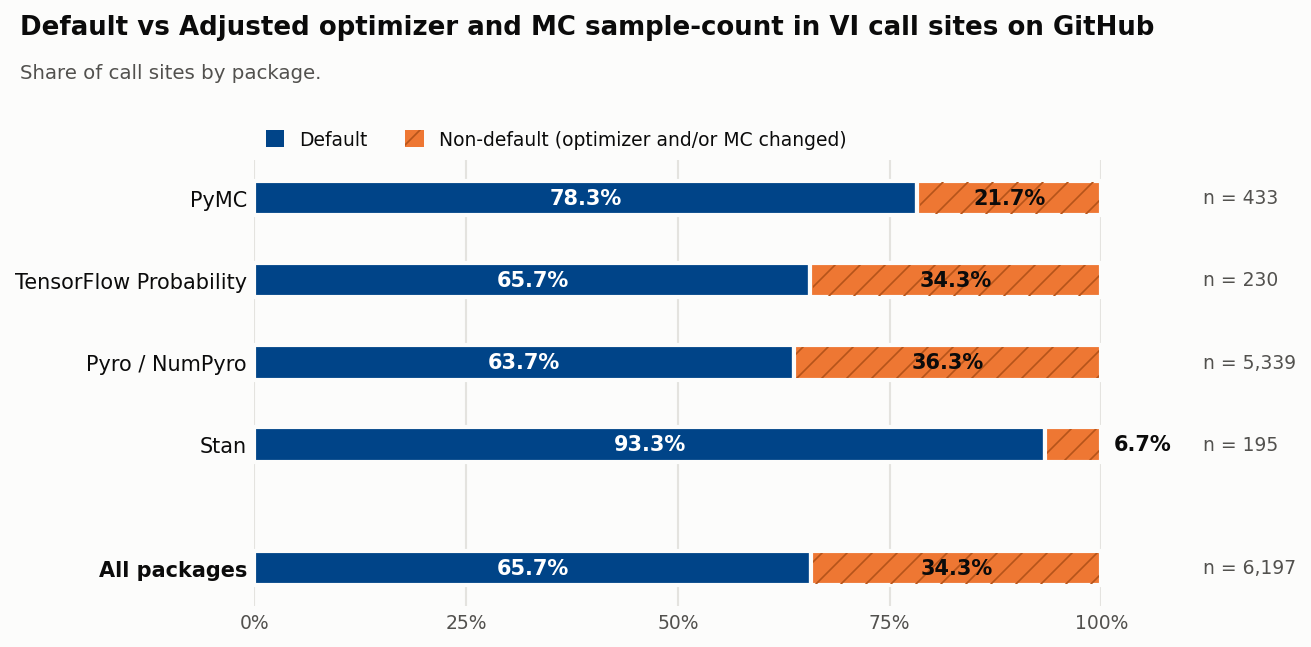

In [4]:
plot_default_share(
    summary,
    title="Default vs Adjusted optimizer and MC sample-count in VI call sites on GitHub",
    subtitle="Share of call sites by package.",
    non_default_label="Non-default (optimizer and/or MC changed)",
    filename="default_vs_nondefault_by_package",
)

**Reading the chart:** each bar counts **call sites**, not repositories. One SVI configuration
can contribute several rows (the `SVI(...)` construction, its guide constructor, and each
`svi.step()` call), so packages with many step calls (Pyro) carry more weight in the overall bar.
The figure is saved to `data/reports/figures/` as PNG and SVG.

## Per repository

A repository can contain many call sites, some default and some not. Here a repository
counts as **non-default** if *any* of its call sites changes the optimizer or MC/sample count,
and **default** only if every call site leaves both at the default. This is the same rule
`repo_level_summary.csv` uses for `adjusts_anything`.

Each package bar counts the repositories that use that package; a repository using two
packages appears in both bars. The **All packages** bar counts each repository once.

In [5]:
def summarize_repos(frame: pd.DataFrame) -> pd.Series:
    """Collapse call sites to one row per repository (non-default if any call
    site is non-default), then count default vs. non-default repositories."""
    repo_usage = frame.groupby("repo_full_name")["usage"].agg(
        lambda usages: "Non-default" if (usages == "Non-default").any() else "Default"
    )
    return summarize(repo_usage.to_frame("usage"))

repo_summary = scored.groupby("package_group").apply(summarize_repos, include_groups=False).loc[order]
repo_summary.loc["All packages"] = summarize_repos(scored)
repo_summary[["default", "non_default", "total"]] = repo_summary[["default", "non_default", "total"]].astype(int)

# Cross-check the overall numbers against repo_level_summary.csv.
repo_level = pd.read_csv(REPORTS_DIR / "repo_level_summary.csv")
assert len(repo_level) == repo_summary.loc["All packages", "total"]
assert (repo_level["adjusts_anything"].astype(str) == "True").sum() == repo_summary.loc["All packages", "non_default"]

repo_summary.style.format({"default_pct": "{:.1f}%", "non_default_pct": "{:.1f}%", "default": "{:,}", "non_default": "{:,}", "total": "{:,}"})

,default,non_default,total,default_pct,non_default_pct
package_group,,,,,
PyMC,110,33,143,76.9%,23.1%
TensorFlow Probability,47,28,75,62.7%,37.3%
Pyro / NumPyro,525,395,920,57.1%,42.9%
Stan,58,3,61,95.1%,4.9%
All packages,721,455,"1,176",61.3%,38.7%


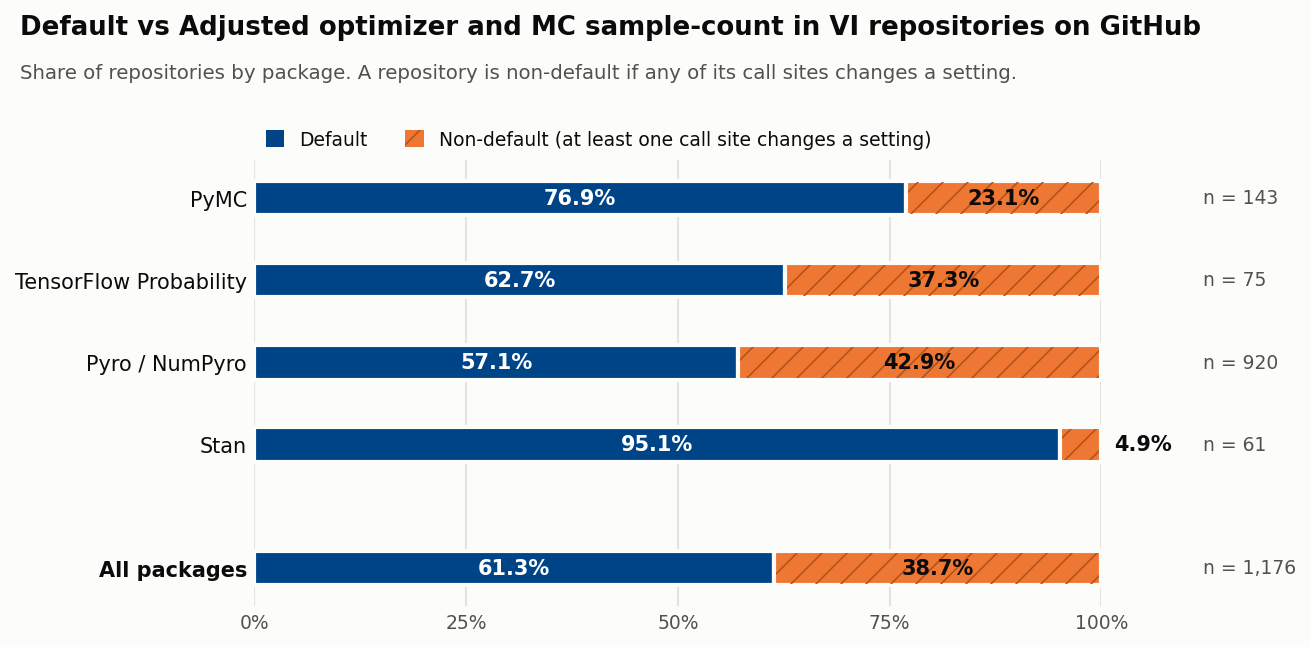

In [6]:
plot_default_share(
    repo_summary,
    title="Default vs Adjusted optimizer and MC sample-count in VI repositories on GitHub",
    subtitle="Share of repositories by package. A repository is non-default if any of its call sites changes a setting.",
    non_default_label="Non-default (at least one call site changes a setting)",
    filename="default_vs_nondefault_by_package_repos",
)